In [1]:

from google.colab import files
uploaded = files.upload()


Saving iris task 1.csv to iris task 1 (1).csv


In [2]:

import pandas as pd

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (150, 5)

First 5 rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Column names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Summary Statistics:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Duplicate rows: 1

Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


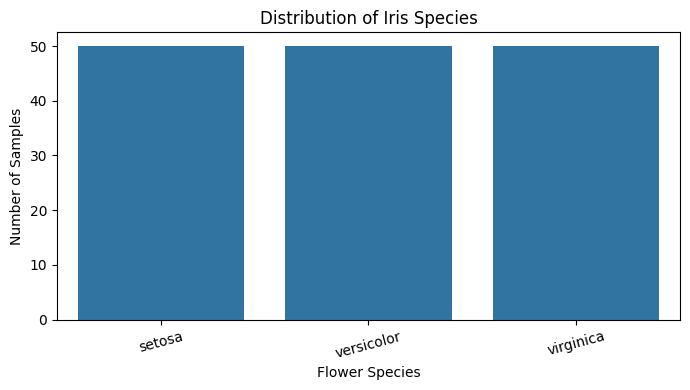

In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display dataset information
print("Dataset Information:")
df.info()

# Summary statistics
print("\nSummary Statistics:")
display(df.describe())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Identify the species column
species_col = next(
    (col for col in df.columns if col.strip().lower() in ["species", "class", "target"]),
    None
)

if species_col is None:
    raise ValueError("Target column not found. Check the column names printed earlier.")

# Count each flower species
print("\nSpecies Distribution:")
print(df[species_col].value_counts())

# Plot species distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x=species_col)
plt.title("Distribution of Iris Species")
plt.xlabel("Flower Species")
plt.ylabel("Number of Samples")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [4]:

from sklearn.model_selection import train_test_split

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Separate input features and target
X = df.drop(columns=[species_col])
y = df[species_col]

# Split data: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data preparation completed!")
print("Total rows after cleaning:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of input features:", X.shape[1])

print("\nTraining species distribution:")
print(y_train.value_counts())

print("\nTesting species distribution:")
print(y_test.value_counts())


Data preparation completed!
Total rows after cleaning: 149
Training samples: 119
Testing samples: 30
Number of input features: 4

Training species distribution:
species
setosa        40
versicolor    40
virginica     39
Name: count, dtype: int64

Testing species distribution:
species
versicolor    10
virginica     10
setosa        10
Name: count, dtype: int64


In [5]:

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Model 1: Logistic Regression with feature scaling
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_model.fit(X_train, y_train)

# Model 2: Decision Tree Classifier
decision_tree_model = DecisionTreeClassifier(random_state=42)
decision_tree_model.fit(X_train, y_train)

print("Both models trained successfully!")
print("1. Logistic Regression")
print("2. Decision Tree Classifier")


Both models trained successfully!
1. Logistic Regression
2. Decision Tree Classifier


In [6]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import pandas as pd

# Store both trained models
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model
}

results = []

for name, model in models.items():
    # Predict species for the test data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })

    print(f"\n{'=' * 45}")
    print(f"Classification Report: {name}")
    print("=" * 45)
    print(classification_report(y_test, y_pred, zero_division=0))

# Display a comparison table
results_df = pd.DataFrame(results)
display(results_df.round(4))



Classification Report: Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Classification Report: Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


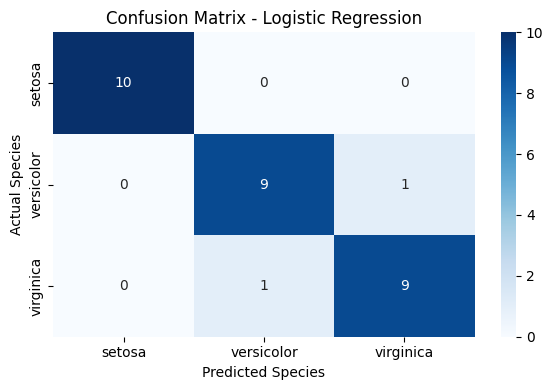

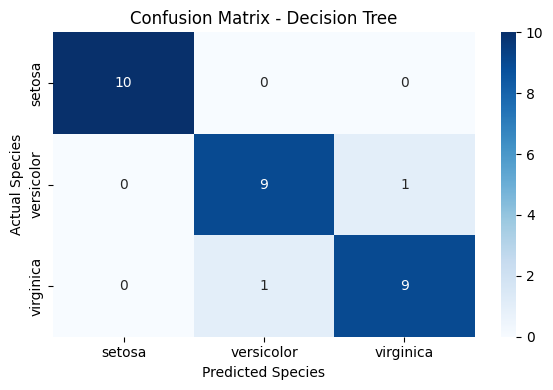

In [7]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Create confusion matrices for both models
for name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=model.classes_,
        yticklabels=model.classes_
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Species")
    plt.ylabel("Actual Species")
    plt.tight_layout()
    plt.show()


,Feature,Importance
2,petal_length,0.5612
3,petal_width,0.4031
1,sepal_width,0.0294
0,sepal_length,0.0063


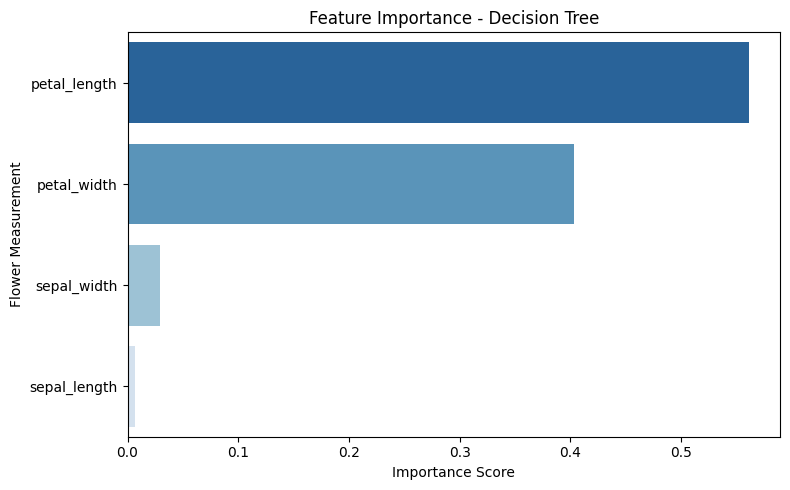

In [8]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance from the trained Decision Tree
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": decision_tree_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

# Display importance values
display(importance_df.round(4))

# Plot feature importance
plt.figure(figsize=(8, 5))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="Blues_r",
    legend=False
)

plt.title("Feature Importance - Decision Tree")
plt.xlabel("Importance Score")
plt.ylabel("Flower Measurement")
plt.tight_layout()
plt.show()


In [9]:

# Final model comparison and project conclusion

results_df = results_df.sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)

print("FINAL MODEL COMPARISON")
display(results_df.round(4))

best_accuracy = results_df["Accuracy"].max()
best_models = results_df.loc[
    results_df["Accuracy"] == best_accuracy, "Model"
].tolist()

print("\nPROJECT CONCLUSION")
print("-" * 50)
print("Dataset: Iris flower dataset")
print("Original records: 150")
print("Records after duplicate removal:", len(df))
print("Input features:", X.shape[1])
print("Test samples:", len(X_test))
print("Models: Logistic Regression and Decision Tree")
print(f"Best test accuracy: {best_accuracy:.2%}")
print("Model(s) with the highest accuracy:", ", ".join(best_models))

print("\nBoth models were evaluated using accuracy, precision,")
print("recall, F1-score, and confusion matrices.")
print("Feature importance was also examined for the Decision Tree.")


FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333



PROJECT CONCLUSION
--------------------------------------------------
Dataset: Iris flower dataset
Original records: 150
Records after duplicate removal: 149
Input features: 4
Test samples: 30
Models: Logistic Regression and Decision Tree
Best test accuracy: 93.33%
Model(s) with the highest accuracy: Logistic Regression, Decision Tree

Both models were evaluated using accuracy, precision,
recall, F1-score, and confusion matrices.
Feature importance was also examined for the Decision Tree.
